In [1]:
# ============================================================
# 单元格 1：导入依赖 + 固定随机种子 + 指定设备
# ============================================================
import os
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from PIL import Image

# 固定随机种子：保证权重初始化、DataLoader shuffle 等可复现。
# 注意：这只保证"同机同环境"可复现，跨机器仍可能有细微差异。
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # CPU 环境下无副作用，保留以便将来迁移

set_seed(42)

# 本机无 GPU，显式用 CPU，避免代码里隐式假设 CUDA 可用。
device = torch.device("cpu")
print("device:", device)

device: cpu


In [2]:
# ============================================================
# 单元格 2：声明数据路径，确认三个子集和类别目录都存在
# ============================================================
DATA_ROOT = Path("D:\\image\\process_1024")
TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR   = DATA_ROOT / "val"
TEST_DIR  = DATA_ROOT / "test"

# 逐个检查目录是否存在，并打印类别子目录名，防止路径写错。
for split, d in [("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR)]:
    assert d.exists(), f"找不到目录: {d}"
    classes = sorted([p.name for p in d.iterdir() if p.is_dir()])
    print(f"{split}: classes = {classes}")

train: classes = ['luo', 'miku']
val: classes = ['luo', 'miku']
test: classes = ['luo', 'miku']


In [ ]:
# ============================================================
# 单元格 3：定义两套 transforms
# 关键原则：
#   1) 训练集用随机增强；验证/测试集必须确定性，不能随机。
#   2) 1024 原图对 CPU 训练太大，先缩到 224 附近。
#   3) ToTensor 把 HWC uint8 [0,255] 转成 CHW float [0,1]。
#   4) Normalize 做 (x - mean) / std。
#      当前未用预训练模型，先用 0.5/0.5 简化；
#      后续改用 ImageNet 预训练模型时，必须换成：
#      mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]
# ============================================================

from torchvision import transforms

MEAN = [0.5, 0.5, 0.5]
STD = [0.5, 0.5, 0.5]

# 训练集：随机增强 + 转张量 + 标准化
train_tf = transforms.Compose([
    # 从原图随机裁剪一块区域再缩放到 224x224：
    # - 保持正方形输出，便于 batch 堆叠
    # - scale=(0.7, 1.0) 表示裁剪面积占原图 70%~100%，避免裁得太狠
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    # 水平翻转：图像二分类最安全、最常用的增强
    transforms.RandomHorizontalFlip(p=0.5),    
    # HWC uint8 [0,255] -> CHW float [0,1]
    # PIL Image -> FloatTensor，形状 [C,H,W]，取值范围 [0,1]
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),  # 值域大致变为 [-1, 1]
])

# 验证/测试集：只做确定性 resize + 转张量 + 标准化，不能有随机增强
eval_tf = transforms.Compose([
    # 只给一个数 256：短边缩到 256，长边按比例缩放，保持长宽比
    transforms.Resize(256),
    # 中心裁剪 224x224：与训练输出尺寸一致
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

In [4]:
# ============================================================
# 单元格 4：用 ImageFolder 构建 Dataset
# ImageFolder 返回 (image_tensor, label)，label 为 int。
# 训练集用 train_tf，验证/测试集用 eval_tf——这一步千万别混。
# ============================================================
train_ds = ImageFolder(root=str(TRAIN_DIR), transform=train_tf)
val_ds   = ImageFolder(root=str(VAL_DIR),   transform=eval_tf)
test_ds  = ImageFolder(root=str(TEST_DIR),  transform=eval_tf)

# 打印类别到索引的映射：决定"正类"是 0 还是 1
print("class_to_idx:", train_ds.class_to_idx)
print("num_classes:", len(train_ds.classes))
print("sizes:", len(train_ds), len(val_ds), len(test_ds))

# 取一个样本检查形状和 dtype
img, label = train_ds[0]
print("image shape:", img.shape, "dtype:", img.dtype, "label:", label)
# 预期：torch.Size([3, 224, 224]), torch.float32, label 为 0 或 1

class_to_idx: {'luo': 0, 'miku': 1}
num_classes: 2
sizes: 1920 240 240
image shape: torch.Size([3, 224, 224]) dtype: torch.float32 label: 0


In [ ]:
# ============================================================
# 单元格 5：自定义 Dataset 模板
# 当需要返回文件名、多标签、复杂采样时使用。
# 当前目录规范，ImageFolder 已够用；这里只给大模型只给出了模板，方便后续扩展。我认为本次项目用不到，就没抄过来。
# ============================================================


In [6]:
# ============================================================
# 单元格 6：构建 DataLoader
# 关键参数：
#   batch_size  : CPU 轻薄本建议 8/16/32，先用 16
#   shuffle     : 训练集 True，验证/测试 False
#   num_workers : Jupyter + Windows 建议先 0；稳定后再试 2
#   pin_memory  : 只对 CUDA 有意义，CPU 环境设 False
# ============================================================
BATCH_SIZE = 16

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,        # 训练集打乱，提升随机性
    num_workers=0,       # Jupyter 下先用 0，避免 spawn 相关卡住
    pin_memory=False,
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,       # 验证集不打乱，便于逐样本对齐分析
    num_workers=0,
    pin_memory=False,
)
test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

print("batches:", len(train_loader), len(val_loader), len(test_loader))

batches: 120 15 15


In [7]:
# ============================================================
# 单元格 7：取出一个 batch，确认形状、dtype、值域、标签范围
# 这是数据管线的"验收检查点"，不对就先别往下训。
# ============================================================
images, labels = next(iter(train_loader))
print("images:", images.shape, images.dtype,
      "min/max:", images.min().item(), images.max().item())
print("labels:", labels.shape, labels.dtype, "unique:", torch.unique(labels))

# 预期：
# images: torch.Size([16, 3, 224, 224]), float32, 值域大致 [-1, 1]
# labels: torch.Size([16]), int64, 取值 {0, 1}

images: torch.Size([16, 3, 224, 224]) torch.float32 min/max: -1.0 1.0
labels: torch.Size([16]) torch.int64 unique: tensor([0, 1])


In [8]:
# ============================================================
# 单元格 8：最小 CNN 骨架（详细注释版）
#
# 设计约定：
#   1) 输出"单 logit"，不在 forward 里加 Sigmoid；
#      交给 nn.BCEWithLogitsLoss，它内部做 Sigmoid+BCE，数值更稳。
#   2) 网络拆成 features（卷积特征提取）和 classifier（分类头）两段，
#      便于后续换分类头做迁移学习。
#   3) 所有层都是 nn.Module 的子模块，model.to(device) 会递归搬运。
#
# 维度流（B 为 batch size）：
#   [B,3,224,224]
#     -> Conv2d(3->16,k3,p1)   [B,16,224,224]   尺寸不变：k=3,p=1,s=1
#     -> ReLU                  [B,16,224,224]   逐元素，不变形
#     -> MaxPool2d(2)          [B,16,112,112]   k=2,s=2 默认，H/W 减半
#     -> Conv2d(16->32,k3,p1)  [B,32,112,112]   尺寸不变
#     -> ReLU                  [B,32,112,112]
#     -> MaxPool2d(2)          [B,32,56,56]     H/W 再减半
#     -> AdaptiveAvgPool2d(1)  [B,32,1,1]       每通道全局平均
#     -> Flatten               [B,32]           保留 batch，拉平其余维
#     -> Linear(32->1)         [B,1]            单 logit
# ============================================================
class TinyCNN(nn.Module):
    def __init__(self, num_classes=1):
        # 必须最先调用父类初始化：
        # 它建立子模块/参数的注册表，之后 self.xxx = nn.Xxx(...)
        # 才能被 parameters()、to()、state_dict() 正确识别。
        super().__init__()

        # ---------- 特征提取段：卷积 + 激活 + 池化 交替 ----------
        self.features = nn.Sequential(
            # 第 1 个卷积：3 通道 RGB -> 16 个特征图
            # kernel_size=3, padding=1, stride=1(默认)
            # 输出尺寸 = floor((224 + 2*1 - 3)/1) + 1 = 224，尺寸不变
            # 权重形状 [16, 3, 3, 3]，偏置 [16]
            nn.Conv2d(in_channels=3, out_channels=16,
                      kernel_size=3, padding=1),

            # 逐元素 max(0,x)，不改变形状，无参数，引入非线性
            # inplace=True：原地修改输入，省一份中间内存；
            # 该输出只往下传，不会影响别的分支，所以安全。
            nn.ReLU(inplace=True),

            # 2x2 最大池化，stride 默认等于 kernel_size=2（非重叠）
            # 每个通道独立：通道数 16 不变，H/W 各减半
            # 输出 = floor((224-2)/2)+1 = 112 -> [B,16,112,112]
            # 无参数；反向时梯度只回传给窗口内最大值位置
            nn.MaxPool2d(kernel_size=2),

            # 第 2 个卷积：16 -> 32 通道
            # k=3,p=1,s=1，H/W 保持 112 不变
            # 权重形状 [32, 16, 3, 3]，偏置 [32]
            nn.Conv2d(in_channels=16, out_channels=32,
                      kernel_size=3, padding=1),

            # 同上，逐元素 ReLU
            nn.ReLU(inplace=True),

            # 再次 2x2 非重叠池化
            # 输出 = floor((112-2)/2)+1 = 56 -> [B,32,56,56]
            nn.MaxPool2d(kernel_size=2),
        )

        # ---------- 分类头段：全局池化 + 展平 + 线性 ----------
        self.classifier = nn.Sequential(
            # 自适应全局平均池化：输出空间尺寸固定为 1x1
            # 对每个通道在整张 HxW 上取平均
            # [B,32,56,56] -> [B,32,1,1]
            # "自适应"= 窗口大小由输入尺寸自动决定，
            # 换输入分辨率时这一层不用改。
            # 相比"Flatten 后接大 Linear"，它参数少、更不易过拟合。
            nn.AdaptiveAvgPool2d(output_size=1),

            # 展平：默认 start_dim=1，保留第 0 维 batch
            # [B,32,1,1] -> [B,32]
            # 不能从 dim=0 展平，否则会把 batch 内样本混在一起。
            nn.Flatten(),

            # 线性变换 y = x @ W.T + b
            # 输入 [B,32]，输出 [B,num_classes]=[B,1]
            # 权重 [1,32]，偏置 [1]
            # 输出是"单 logit"（未归一化分数），不是概率。
            # 概率 = sigmoid(logit)，但不在 forward 里做，
            # 因为 BCEWithLogitsLoss 内部会做，数值更稳定。
            nn.Linear(in_features=32, out_features=num_classes),
        )

    def forward(self, x):
        # x: [B,3,224,224]
        # 前向即按 features -> classifier 顺序执行；
        # PyTorch 会自动记录计算图用于反向传播。
        x = self.features(x)    # [B,32,56,56]
        x = self.classifier(x)  # [B,1] 单 logit
        return x

# 实例化并搬到设备（CPU）。
# .to(device) 递归搬运所有子模块参数；
# 训练时数据也要 .to(device)，模型与数据必须同设备。
model = TinyCNN(num_classes=1).to(device)
print(model)

TinyCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [9]:
# ============================================================
# 单元格 9：损失函数、优化器、二分类指标（详细注释版）
#
# 职责划分：
#   criterion  : 定义"预测有多错"，产出标量 loss，驱动反向传播
#   optimizer  : 定义"如何用梯度更新参数"
#   metrics    : 定义"如何把 logit 读成可解释指标"，只用于评估
#
# 形状契约（最重要）：
#   模型输出 logit : [B,1] float32
#   损失用 target  : [B,1] float32，值 {0.0,1.0}
#   指标用 target  : [B]   int64，值 {0,1}
#   损失和指标的 target 形状不同，转换在训练/评估函数里做。
# ============================================================

# ---------- 损失函数 ----------
# BCEWithLogitsLoss = 内部 Sigmoid + BCE，合并成一个数值稳定的算子。
# 输入必须是 logit，不是概率；不要在外面先 sigmoid。
# 数学上 loss(z,y) = max(z,0) - z*y + log(1+exp(-|z|))，
# 避免直接算 log(sigmoid(z)) 在 z 很大/很小时的 inf/NaN。
# 形状要求：input 与 target 形状一致，target 为 float。
criterion = nn.BCEWithLogitsLoss()

# ---------- 优化器 ----------
# Adam 是梯度下降的自适应变体：每个参数维护一阶矩(梯度均值)
# 和二阶矩(梯度平方均值)，按参数维度缩放有效学习率。
# 优点：收敛快、对 lr 不那么敏感，适合快速跑通基线。
# model.parameters() 只包含可学习参数；MaxPool/ReLU 无参数，不参与。
# lr=1e-3 是 Adam 常用起点；后续根据 train/val 曲线再调。
# weight_decay 默认 0，等观察到过拟合再加。
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# ---------- 指标函数 ----------
def binary_metrics_from_logits(logits, targets, threshold=0.5):
    """
    从 logit 计算 acc / precision / recall / f1。

    参数：
        logits   : [B,1] 或 [B]，模型原始输出（未过 sigmoid）
        targets  : [B]    int64 或 float，值 {0,1}
        threshold: 概率阈值，默认 0.5；不平衡时应扫描调优

    返回：
        dict，四个 Python float。注意这是"传入这批数据"的 batch 级指标；
        跨 batch 汇总应先累积 TP/TN/FP/FN 再算比率。
    """
    # logit -> 概率。squeeze(1) 把 [B,1] 压成 [B]；
    # 指定维度 1，避免 batch=1 时 squeeze() 误删 batch 维。
    probs = torch.sigmoid(logits.squeeze(1))

    # 阈值二值化：布尔 [B] -> int64 {0,1}，与 targets 同 dtype 便于逻辑运算。
    preds = (probs >= threshold).long()

    # 统一 targets 为 int64；调用方需保证 targets 是 [B]，
    # 若是 [B,1] 会与 preds 广播成 [B,B]，指标全错。
    targets = targets.long()

    # 混淆矩阵四元素：逐元素布尔与，再求和计数。
    # .item() 把张量取成 Python int，脱离计算图；指标不需反传。
    tp = ((preds == 1) & (targets == 1)).sum().item()  # 正类判对
    tn = ((preds == 0) & (targets == 0)).sum().item()  # 负类判对
    fp = ((preds == 1) & (targets == 0)).sum().item()  # 负类误判为正
    fn = ((preds == 0) & (targets == 1)).sum().item()  # 正类误判为负

    # 比率指标；分母用 max(.,1) 防除零（某类为空时结果为 0 而非 NaN）。
    acc       = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall    = tp / max(tp + fn, 1)
    # F1 是 P/R 调和平均；分母极小值兜底，避免 0/0。
    f1        = 2 * precision * recall / max(precision + recall, 1e-8)

    # 返回 Python float 的 dict：便于打印、记录、画曲线。
    return {"acc": acc, "precision": precision, "recall": recall, "f1": f1}

In [10]:
# ============================================================
# 单元格 10：单 epoch 训练与验证函数
# 训练循环五步：zero_grad -> forward -> loss -> backward -> step
# 验证循环：model.eval() + torch.no_grad()
# ============================================================
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()  # 训练模式：影响 Dropout/BatchNorm 行为
    total_loss, total_n = 0.0, 0
    for images, labels in loader:
        images = images.to(device)
        # BCEWithLogitsLoss 要求 target 为 float 且形状与 logit 一致 [B,1]
        labels = labels.to(device).float().unsqueeze(1)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)  # 按样本数加权
        total_n += images.size(0)
    return total_loss / total_n

@torch.no_grad()
def evaluate(model, loader, criterion, device, threshold=0.5):
    model.eval()   # 评估模式
    total_loss, total_n = 0.0, 0
    all_logits, all_labels = [], []
    for images, labels in loader:
        images = images.to(device)
        labels_dev = labels.to(device).float().unsqueeze(1)
        logits = model(images)
        loss = criterion(logits, labels_dev)
        total_loss += loss.item() * images.size(0)
        total_n += images.size(0)
        all_logits.append(logits.cpu())
        all_labels.append(labels.cpu())
    all_logits = torch.cat(all_logits, dim=0)
    all_labels = torch.cat(all_labels, dim=0)
    metrics = binary_metrics_from_logits(all_logits, all_labels, threshold)
    metrics["loss"] = total_loss / total_n
    return metrics

# 跑 3 个 epoch，观察 train loss 是否下降、val 指标是否合理
EPOCHS = 3
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_metrics = evaluate(model, val_loader, criterion, device)
    print(f"epoch {epoch}: train_loss={train_loss:.4f}, val={val_metrics}")

epoch 1: train_loss=0.6818, val={'acc': 0.6416666666666667, 'precision': 0.646551724137931, 'recall': 0.625, 'f1': 0.635593220338983, 'loss': 0.6612473169962565}
epoch 2: train_loss=0.6339, val={'acc': 0.6541666666666667, 'precision': 0.6390977443609023, 'recall': 0.7083333333333334, 'f1': 0.6719367588932806, 'loss': 0.6231722255547841}
epoch 3: train_loss=0.6093, val={'acc': 0.6583333333333333, 'precision': 0.6319444444444444, 'recall': 0.7583333333333333, 'f1': 0.6893939393939393, 'loss': 0.6312589685122172}


In [11]:
# ============================================================
# 单元格 11：保存 state_dict + 单张推理
# 保存 state_dict 而非整个模型对象，更稳健、更易迁移。
# ============================================================
CKPT = Path("best_model.pt")
torch.save(model.state_dict(), CKPT)

def predict_proba(model, image_tensor, device="cpu"):
    """输入单张已 transform 的图像 [C,H,W]，返回正类概率。"""
    model.eval()
    with torch.no_grad():
        if image_tensor.dim() == 3:
            image_tensor = image_tensor.unsqueeze(0)  # -> [1,C,H,W]
        logit = model(image_tensor.to(device))
        prob = torch.sigmoid(logit).item()
    return prob

# 用验证集第一张图演示推理
img0, label0 = val_ds[0]
p = predict_proba(model, img0, device)
print("true label:", label0, "pred prob:", p, "pred label(0.5):", int(p >= 0.5))

true label: 0 pred prob: 0.36785468459129333 pred label(0.5): 0


In [12]:
# ============================================================
# 单元格 12：多 epoch 训练 + 每轮计时 + 实验数据落盘
#
# 依赖：单元格 1（device/seed）、3（transforms）、4（datasets）、
#       6（loaders）、8（model）、9（criterion/optimizer/metrics）、
#       10（train_one_epoch / evaluate）
#
# 本单元格完成：
#   1) 每轮计时：train / val / epoch / 累计 / ETA
#   2) 每轮指标追加写入 metrics.csv（硬盘，不依赖内存 list）
#   3) last_ckpt.pt：完整状态，支持断点续训
#   4) best_model.pt：验证集 F1 最高的纯 state_dict，用于推理
#   5) config.json：预处理、类别映射、超参，保证推理可复现
#
# 落盘结构：
#   runs/<RUN_ID>/
#     ├── config.json     配置与 class_to_idx
#     ├── metrics.csv     每轮一行，权威实验记录
#     ├── last_ckpt.pt    最新完整状态（续训用）
#     └── best_model.pt   val_f1 最高权重（推理用）
# ============================================================
import csv
import json
import time
from datetime import datetime

# ---------- 0. 超参统一入口 ----------
# 改训练轮数只改这里；LR 若改，需重建 optimizer（单元格 9）。
NUM_EPOCHS = 10

# ---------- 1. 创建本次实验目录 ----------
# 时间戳命名：每次运行独立目录，不覆盖历史实验。
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = Path("runs") / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)

METRICS_CSV = RUN_DIR / "metrics.csv"
CONFIG_JSON = RUN_DIR / "config.json"
LAST_CKPT   = RUN_DIR / "last_ckpt.pt"
BEST_CKPT   = RUN_DIR / "best_model.pt"

print("run dir:", RUN_DIR.resolve())

# ---------- 2. 落盘配置 ----------
# 推理时必须能还原：图像尺寸、归一化参数、类别映射。
# 缺任何一项都可能导致"模型不报错但结果全错"的静默 bug。
config = {
    "run_id": RUN_ID,
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "num_epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "lr": optimizer.param_groups[0]["lr"],
    "optimizer": "Adam",
    "loss": "BCEWithLogitsLoss",
    "mean": MEAN,
    "std": STD,
    "class_to_idx": train_ds.class_to_idx,
    "num_train": len(train_ds),
    "num_val": len(val_ds),
    "num_test": len(test_ds),
    "device": str(device),
}
with open(CONFIG_JSON, "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

# ---------- 3. 初始化 CSV 表头 ----------
# 每轮追加一行；is_best 标记该轮是否刷新 best，便于后续筛选。
CSV_FIELDS = [
    "epoch", "train_loss",
    "val_loss", "val_acc", "val_precision", "val_recall", "val_f1",
    "train_seconds", "val_seconds", "epoch_seconds", "elapsed_seconds",
    "lr", "is_best",
]
with open(METRICS_CSV, "w", newline="", encoding="utf-8") as f:
    csv.DictWriter(f, fieldnames=CSV_FIELDS).writeheader()

# ---------- 4. 多 epoch 训练 ----------
best_val_f1 = -1.0
total_start = time.perf_counter()
epoch_times = []   # 仅用于本次会话算 ETA；权威记录在 CSV

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()

    # --- 训练一个 epoch（内部 model.train()，更新参数） ---
    t0 = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    train_time = time.perf_counter() - t0

    # --- 验证一个 epoch（内部 model.eval() + no_grad，不更新参数） ---
    t1 = time.perf_counter()
    val_metrics = evaluate(model, val_loader, criterion, device)
    val_time = time.perf_counter() - t1

    epoch_time = time.perf_counter() - epoch_start
    elapsed = time.perf_counter() - total_start
    epoch_times.append(epoch_time)

    # --- 是否刷新 best ---
    # 主指标取 val_f1；若业务更关心 recall，改成 val_metrics["recall"]
    is_best = val_metrics["f1"] > best_val_f1
    if is_best:
        best_val_f1 = val_metrics["f1"]

    # --- 追加写 CSV ---
    # 每轮 open/append 一次：进程崩溃时已写行不丢；CSV 量小，开销可忽略。
    row = {
        "epoch": epoch,
        "train_loss": round(train_loss, 6),
        "val_loss": round(val_metrics["loss"], 6),
        "val_acc": round(val_metrics["acc"], 6),
        "val_precision": round(val_metrics["precision"], 6),
        "val_recall": round(val_metrics["recall"], 6),
        "val_f1": round(val_metrics["f1"], 6),
        "train_seconds": round(train_time, 3),
        "val_seconds": round(val_time, 3),
        "epoch_seconds": round(epoch_time, 3),
        "elapsed_seconds": round(elapsed, 3),
        "lr": optimizer.param_groups[0]["lr"],
        "is_best": int(is_best),
    }
    with open(METRICS_CSV, "a", newline="", encoding="utf-8") as f:
        csv.DictWriter(f, fieldnames=CSV_FIELDS).writerow(row)

    # --- 保存完整 last checkpoint（续训用） ---
    # 存 dict 而非纯 state_dict；optimizer 状态必须一起存，
    # 否则续训后 Adam 的一阶/二阶矩重置，相当于热启动新优化器。
    torch.save({
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "best_val_f1": best_val_f1,
        "class_to_idx": train_ds.class_to_idx,
        "config": config,
    }, LAST_CKPT)

    # --- 保存 best 纯权重（推理用） ---
    # 只存 state_dict，保持与单元格 11 的 load_state_dict 兼容。
    if is_best:
        torch.save(model.state_dict(), BEST_CKPT)

    # --- 打印摘要 + ETA ---
    avg_epoch = sum(epoch_times) / len(epoch_times)
    eta = avg_epoch * (NUM_EPOCHS - epoch)
    print(
        f"[{epoch:02d}/{NUM_EPOCHS}] "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_metrics['loss']:.4f} "
        f"acc={val_metrics['acc']:.4f} "
        f"P={val_metrics['precision']:.4f} "
        f"R={val_metrics['recall']:.4f} "
        f"F1={val_metrics['f1']:.4f} | "
        f"{epoch_time:.1f}s (tr {train_time:.1f}s / va {val_time:.1f}s) "
        f"ETA {eta/60:.1f}min"
        + ("  *best*" if is_best else "")
    )

print(f"\ndone. best val_f1={best_val_f1:.4f}")
print("metrics :", METRICS_CSV.resolve())
print("best ckpt:", BEST_CKPT.resolve())

run dir: D:\AI_study\learn\image-binary-clf\runs\20261102_214648
[01/10] train_loss=0.5960 | val_loss=0.6016 acc=0.6750 P=0.7059 R=0.6000 F1=0.6486 | 44.2s (tr 39.9s / va 4.2s) ETA 6.6min  *best*
[02/10] train_loss=0.5836 | val_loss=0.6027 acc=0.6792 P=0.6463 R=0.7917 F1=0.7116 | 42.4s (tr 38.2s / va 4.2s) ETA 5.8min  *best*
[03/10] train_loss=0.5791 | val_loss=0.5926 acc=0.6667 P=0.6587 R=0.6917 F1=0.6748 | 48.2s (tr 43.1s / va 5.1s) ETA 5.2min
[04/10] train_loss=0.5683 | val_loss=0.5963 acc=0.6917 P=0.6620 R=0.7833 F1=0.7176 | 47.0s (tr 42.6s / va 4.4s) ETA 4.5min  *best*
[05/10] train_loss=0.5659 | val_loss=0.5742 acc=0.7167 P=0.7063 R=0.7417 F1=0.7236 | 46.7s (tr 42.2s / va 4.5s) ETA 3.8min  *best*
[06/10] train_loss=0.5560 | val_loss=0.5720 acc=0.7042 P=0.7248 R=0.6583 F1=0.6900 | 48.3s (tr 44.4s / va 3.9s) ETA 3.1min
[07/10] train_loss=0.5589 | val_loss=0.5858 acc=0.6833 P=0.7391 R=0.5667 F1=0.6415 | 45.8s (tr 41.0s / va 4.8s) ETA 2.3min
[08/10] train_loss=0.5505 | val_loss=0.596

In [14]:
# ============================================================
# 单元格 13：加载 best_model.pt，在完整测试集上评估
#
# 依赖：单元格 1（device）、3（eval_tf）、8（TinyCNN）、
#       9（binary_metrics_from_logits）
#
# 关键约束：
#   1) 测试集用 eval_tf，确定性，无随机增强
#   2) model.eval() + torch.no_grad()，不更新参数
#   3) 测试集只评估一次，不用于调参/调阈值
#   4) 正类 = class_to_idx 中索引 1 的类（当前是 miku）
# ============================================================
import csv
from pathlib import Path

import torch
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

# ---------- 1. 路径：指向你实际的 run 目录 ----------
RUN_DIR   = Path("runs/20261102_214648")
BEST_CKPT = RUN_DIR / "best_model.pt"
TEST_DIR  = Path("D:\\image\\process_1024\\test")

assert BEST_CKPT.exists(), f"找不到权重: {BEST_CKPT}"
assert TEST_DIR.exists(),  f"找不到测试集: {TEST_DIR}"

# ---------- 2. 重建模型结构，再加载 state_dict ----------
# best_model.pt 只存了权重，不存结构，所以必须先实例化 TinyCNN。
# 结构必须与训练时完全一致，否则 load_state_dict 会报 key 不匹配。
model = TinyCNN(num_classes=1).to(device)
state_dict = torch.load(BEST_CKPT, map_location=device)
model.load_state_dict(state_dict)   # strict=True 默认，结构不一致会直接报错
model.eval()                        # 切评估模式：影响 Dropout/BatchNorm 等
print("loaded:", BEST_CKPT.resolve())

# ---------- 3. 用 eval_tf 重建 test_ds / test_loader ----------
# 不依赖之前单元格的 test_ds，显式用当前 eval_tf，避免用到旧 transform。
test_ds = ImageFolder(root=str(TEST_DIR), transform=eval_tf)
test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,   # 与训练一致即可，评估时不影响指标
    shuffle=False,           # 评估不打乱，便于逐样本对齐
    num_workers=0,
    pin_memory=False,
)

print("test class_to_idx:", test_ds.class_to_idx)
print("test size:", len(test_ds))
assert test_ds.class_to_idx == train_ds.class_to_idx, \
    "测试集类别映射与训练集不一致，标签语义会错"

# ---------- 4. 遍历测试集，收集全部 logits 和 labels ----------
# 不做 batch 级指标再平均；先 cat 成全集，再一次性算，得到全集级指标。
all_logits, all_labels = [], []
with torch.no_grad():                     # 评估不需要建计算图
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)            # [B,1] 单 logit
        all_logits.append(logits.cpu())
        all_labels.append(labels.cpu())   # [B] int64

all_logits = torch.cat(all_logits, dim=0)  # [N,1]
all_labels = torch.cat(all_labels, dim=0)  # [N]
print("logits:", all_logits.shape, "labels:", all_labels.shape)

# ---------- 5. 阈值 0.5 下的全集指标 + 混淆矩阵 ----------
# 复用单元格 9 的函数；它期望 targets 是 [B]，这里 all_labels 就是 [N]。
test_metrics = binary_metrics_from_logits(all_logits, all_labels, threshold=0.5)

# 单独补一个 loss，便于和验证集 val_loss 对比。
# BCEWithLogitsLoss 要求 input 与 target 形状一致，target 为 float。
criterion_eval = torch.nn.BCEWithLogitsLoss()
test_loss = criterion_eval(
    all_logits, all_labels.float().unsqueeze(1)
).item()

# 手动算 TP/TN/FP/FN，便于解释 P/R 来源
probs = torch.sigmoid(all_logits.squeeze(1))
preds = (probs >= 0.5).long()
tp = ((preds == 1) & (all_labels == 1)).sum().item()
tn = ((preds == 0) & (all_labels == 0)).sum().item()
fp = ((preds == 1) & (all_labels == 0)).sum().item()
fn = ((preds == 0) & (all_labels == 1)).sum().item()

print("\n[test @ threshold=0.5]")
print(f"loss={test_loss:.4f} acc={test_metrics['acc']:.4f} "
      f"P={test_metrics['precision']:.4f} R={test_metrics['recall']:.4f} "
      f"F1={test_metrics['f1']:.4f}")
print(f"TP={tp} TN={tn} FP={fp} FN={fn}")

# ---------- 6. 测试结果落盘（只写一次，作为最终报告） ----------
TEST_CSV = RUN_DIR / "test_metrics.csv"
with open(TEST_CSV, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["threshold", "loss", "acc", "precision",
                    "recall", "f1", "tp", "tn", "fp", "fn"],
    )
    writer.writeheader()
    writer.writerow({
        "threshold": 0.5,
        "loss": round(test_loss, 6),
        "acc": round(test_metrics["acc"], 6),
        "precision": round(test_metrics["precision"], 6),
        "recall": round(test_metrics["recall"], 6),
        "f1": round(test_metrics["f1"], 6),
        "tp": tp, "tn": tn, "fp": fp, "fn": fn,
    })
print("saved:", TEST_CSV.resolve())

loaded: D:\AI_study\learn\image-binary-clf\runs\20261102_214648\best_model.pt
test class_to_idx: {'luo': 0, 'miku': 1}
test size: 240
logits: torch.Size([240, 1]) labels: torch.Size([240])

[test @ threshold=0.5]
loss=0.5770 acc=0.7250 P=0.6957 R=0.8000 F1=0.7442
TP=96 TN=78 FP=42 FN=24
saved: D:\AI_study\learn\image-binary-clf\runs\20261102_214648\test_metrics.csv


saved: D:\AI_study\learn\image-binary-clf\runs\20261102_214648\training_curves.png


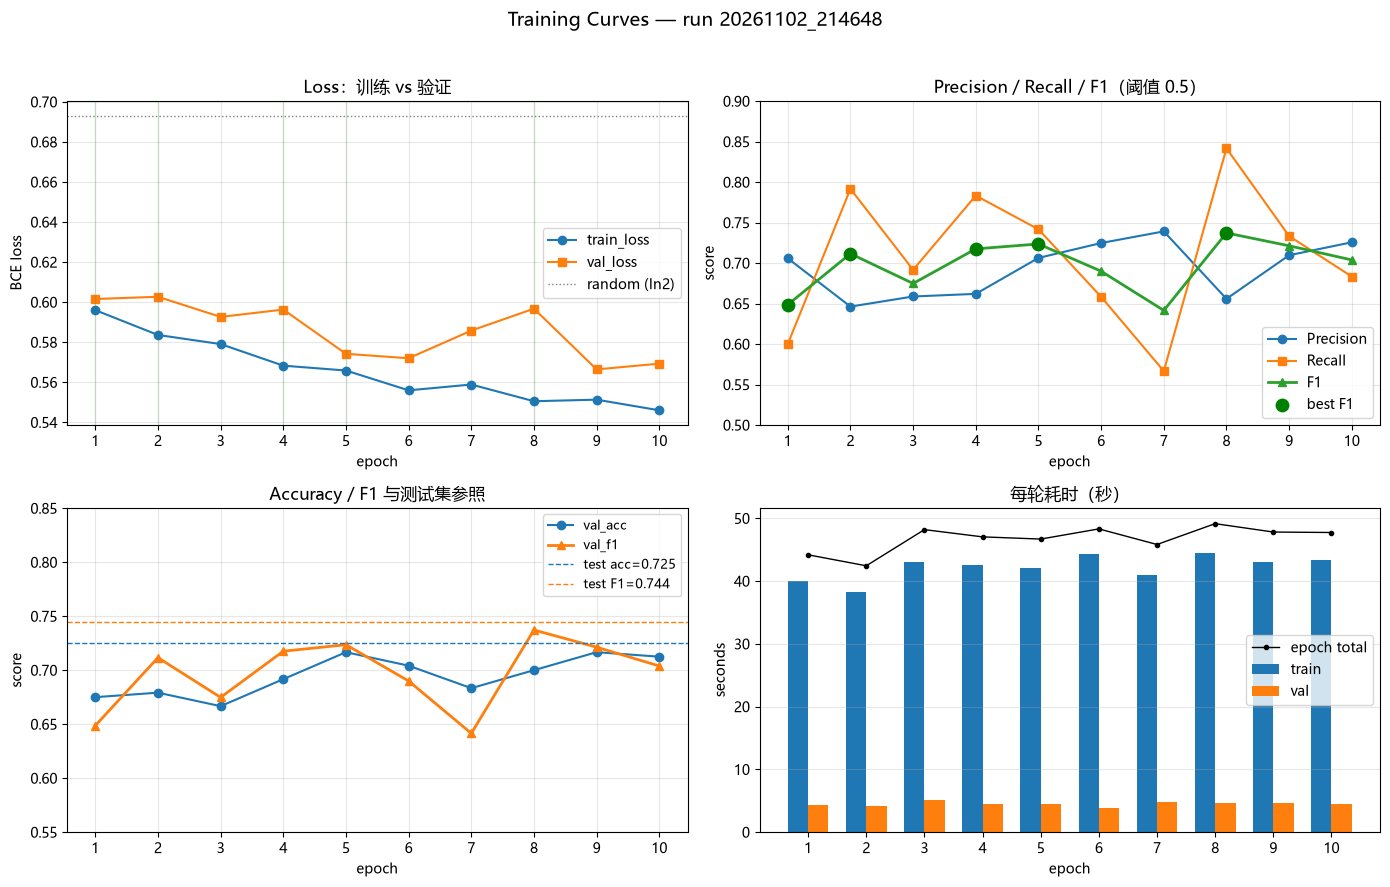

In [15]:
# ============================================================
# 单元格 14：训练过程可视化（2x2 子图）
#
# 依赖：单元格 12 生成的 metrics.csv；可选单元格 13 的测试集指标
#
# 四个子图各回答一个问题：
#   (0,0) Loss      : 模型在训练集/验证集上"错得多不多"，看是否过拟合
#   (0,1) P/R/F1    : 二值判决质量，看 P/R 是否反向摆动
#   (1,0) Acc/F1    : 整体与折中指标，配合 best 标记看选模是否合理
#   (1,1) 耗时      : 每轮 train/val/epoch 用时，判断瓶颈与稳定性
#
# 设计取舍：
#   - lr 全程恒定 0.001，单独画一条直线无信息量，不画
#   - best 用散点 + 竖线标出，避免"最高点在哪轮"靠肉眼找
#   - 测试集指标画水平虚线，作为"验证集估计是否可信"的参照
#   - 图保存到 run 目录，不依赖 notebook 内存
# ============================================================
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 0. 中文字体：Windows 常用 Microsoft YaHei / SimHei ----------
# 若中文显示为方框，把列表换成系统已装字体，或改用英文标签。
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False   # 负号正常显示

# ---------- 1. 读 CSV（权威记录），不硬编码数字 ----------
RUN_DIR = Path("runs/20261102_214648")
df = pd.read_csv(RUN_DIR / "metrics.csv")
assert len(df) > 0, "metrics.csv 为空"

# 测试集结果（来自单元格 13），用于水平参考线；没有就设 None
TEST_F1  = 0.7442
TEST_ACC = 0.7250

epochs = df["epoch"].values
best_epochs = df.loc[df["is_best"] == 1, "epoch"].values

# ---------- 2. 建 2x2 画布 ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(f"Training Curves — run {RUN_DIR.name}", fontsize=14)

# ============================================================
# 子图 (0,0)：Loss 曲线
# 读法：train 持续降 + val 横盘/上升 = 过拟合信号
# 两线不可直接比绝对值（增强/模式/时间点不同），只看趋势
# ============================================================
ax = axes[0, 0]
ax.plot(epochs, df["train_loss"], marker="o", label="train_loss")
ax.plot(epochs, df["val_loss"],   marker="s", label="val_loss")
# 随机基线：平衡二分类瞎猜时 BCE = ln2 ≈ 0.693
ax.axhline(0.693, color="gray", linestyle=":", linewidth=1, label="random (ln2)")
# best epoch 竖线：辅助判断"best 出现在 val_loss 什么位置"
for e in best_epochs:
    ax.axvline(e, color="green", alpha=0.15, linewidth=1)
ax.set_title("Loss：训练 vs 验证")
ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss")
ax.set_xticks(epochs)
ax.grid(alpha=0.3); ax.legend()

# ============================================================
# 子图 (0,1)：Precision / Recall / F1
# 读法：P 和 R 通常反向摆动；F1 是二者调和平均，被较小值拉低
# 若 P 高 R 低，说明模型偏保守；R 高 P 低，说明偏激进
# ============================================================
ax = axes[0, 1]
ax.plot(epochs, df["val_precision"], marker="o", label="Precision")
ax.plot(epochs, df["val_recall"],    marker="s", label="Recall")
ax.plot(epochs, df["val_f1"],        marker="^", label="F1", linewidth=2)
# 标出 best F1 点：直接看"最高点"是否稳健，还是单点尖峰
best_rows = df[df["is_best"] == 1]
ax.scatter(best_rows["epoch"], best_rows["val_f1"],
           color="green", s=80, zorder=5, label="best F1")
ax.set_title("Precision / Recall / F1（阈值 0.5）")
ax.set_xlabel("epoch"); ax.set_ylabel("score")
ax.set_xticks(epochs); ax.set_ylim(0.5, 0.9)
ax.grid(alpha=0.3); ax.legend()

# ============================================================
# 子图 (1,0)：Accuracy + F1 + 测试集参考线
# 读法：acc 平滑但会掩盖 P/R 反向变化；
#      测试集水平线若与 val 曲线同量级，说明验证集估计可信
# ============================================================
ax = axes[1, 0]
ax.plot(epochs, df["val_acc"], marker="o", label="val_acc")
ax.plot(epochs, df["val_f1"],  marker="^", label="val_f1", linewidth=2)
if TEST_ACC is not None:
    ax.axhline(TEST_ACC, color="tab:blue", linestyle="--", linewidth=1,
               label=f"test acc={TEST_ACC:.3f}")
if TEST_F1 is not None:
    ax.axhline(TEST_F1, color="tab:orange", linestyle="--", linewidth=1,
               label=f"test F1={TEST_F1:.3f}")
ax.set_title("Accuracy / F1 与测试集参照")
ax.set_xlabel("epoch"); ax.set_ylabel("score")
ax.set_xticks(epochs); ax.set_ylim(0.55, 0.85)
ax.grid(alpha=0.3); ax.legend(fontsize=9)

# ============================================================
# 子图 (1,1)：每轮耗时
# 读法：train 应占大头；val 稳定；epoch 抖动大说明系统负载波动
# 不画 lr：全程恒定 0.001，直线无信息量
# ============================================================
ax = axes[1, 1]
width = 0.35
ax.bar(epochs - width/2, df["train_seconds"], width, label="train")
ax.bar(epochs + width/2, df["val_seconds"],   width, label="val")
ax.plot(epochs, df["epoch_seconds"], color="black", marker=".",
        linewidth=1, label="epoch total")
ax.set_title("每轮耗时（秒）")
ax.set_xlabel("epoch"); ax.set_ylabel("seconds")
ax.set_xticks(epochs)
ax.grid(alpha=0.3, axis="y"); ax.legend()

# ---------- 3. 保存图到 run 目录 ----------
fig.tight_layout(rect=[0, 0, 1, 0.96])   # 给 suptitle 留空间
FIG_PATH = RUN_DIR / "training_curves.png"
fig.savefig(FIG_PATH, dpi=150, bbox_inches="tight")
print("saved:", FIG_PATH.resolve())
plt.show()